In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))
print("Using project root:", project_root)

Using project root: /home/mbz/Documents/PhD/SCD41_DATA


In [2]:
from src.config import PipelineConfig
from src.pipeline import SensorPipeline
from src.logging_utils import setup_logging
config = PipelineConfig.from_yaml(Path("../config/sensors.yaml"))
print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")
setup_logging(config.log_dir, log_name="notebook_run")

pipeline = SensorPipeline(config, force=False)

2025-12-09 20:47:53,710 - root - INFO - Logging initialized. Log file: /home/mbz/Documents/PhD/SCD41_DATA/output/logs/notebook_run_20251209_204753.log


Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


In [ ]:
pipeline.run_all(year=2024, month=9)

In [ ]:
pipeline.run_all(year=2024, month=10)

In [ ]:
# from src.taylor_diagram_custom import TaylorPlotter

# plotter = TaylorPlotter(output_dir=Path("output/plots"))

# # Simple: all sensors
# fig = plotter.plot_from_config(
#     config,
#     title="Taylor Diagram: SCD41 Sensors vs LGR Reference",
#     filename="taylor_all_sensors.png"
# )

# # Selective: only 30m sensors
# fig = plotter.plot_from_config(
#     config,
#     test_sensor_ids=['CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C'],
#     title="Taylor Diagram: 30m Height Sensors",
#     filename="taylor_30m_only.png"
# )

ModuleNotFoundError: No module named 'src.taylor_diagram_custom'

2025-12-09 20:44:46,116 - TaylorDiagram - INFO - Plotting from config: LGR_30M vs ['CO2_SCT1_2M', 'CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C']
2025-12-09 20:44:46,117 - TaylorDiagram - INFO - Creating NORMALIZED Taylor diagram with 4 test sensors
2025-12-09 20:44:46,156 - TaylorDiagram - INFO - Reference sensor: LGR_30M, column: CO2_dry_mean
2025-12-09 20:44:46,168 - TaylorDiagram - INFO - CO2_SCT1_2M: 6722 overlapping data points
2025-12-09 20:44:46,169 - TaylorDiagram - INFO - CO2_SCT1_2M (normalized): r=0.517, σ/σ_ref=200.125, CRMSD'=193.722
2025-12-09 20:44:46,180 - TaylorDiagram - INFO - CO2_30M_A: 4522 overlapping data points
2025-12-09 20:44:46,181 - TaylorDiagram - INFO - CO2_30M_A (normalized): r=0.031, σ/σ_ref=63.683, CRMSD'=63.917
2025-12-09 20:44:46,197 - TaylorDiagram - INFO - CO2_30M_B: 4683 overlapping data points
2025-12-09 20:44:46,199 - TaylorDiagram - INFO - CO2_30M_B (normalized): r=0.122, σ/σ_ref=138.877, CRMSD'=138.121
2025-12-09 20:44:46,212 - TaylorDiagram - INFO - CO

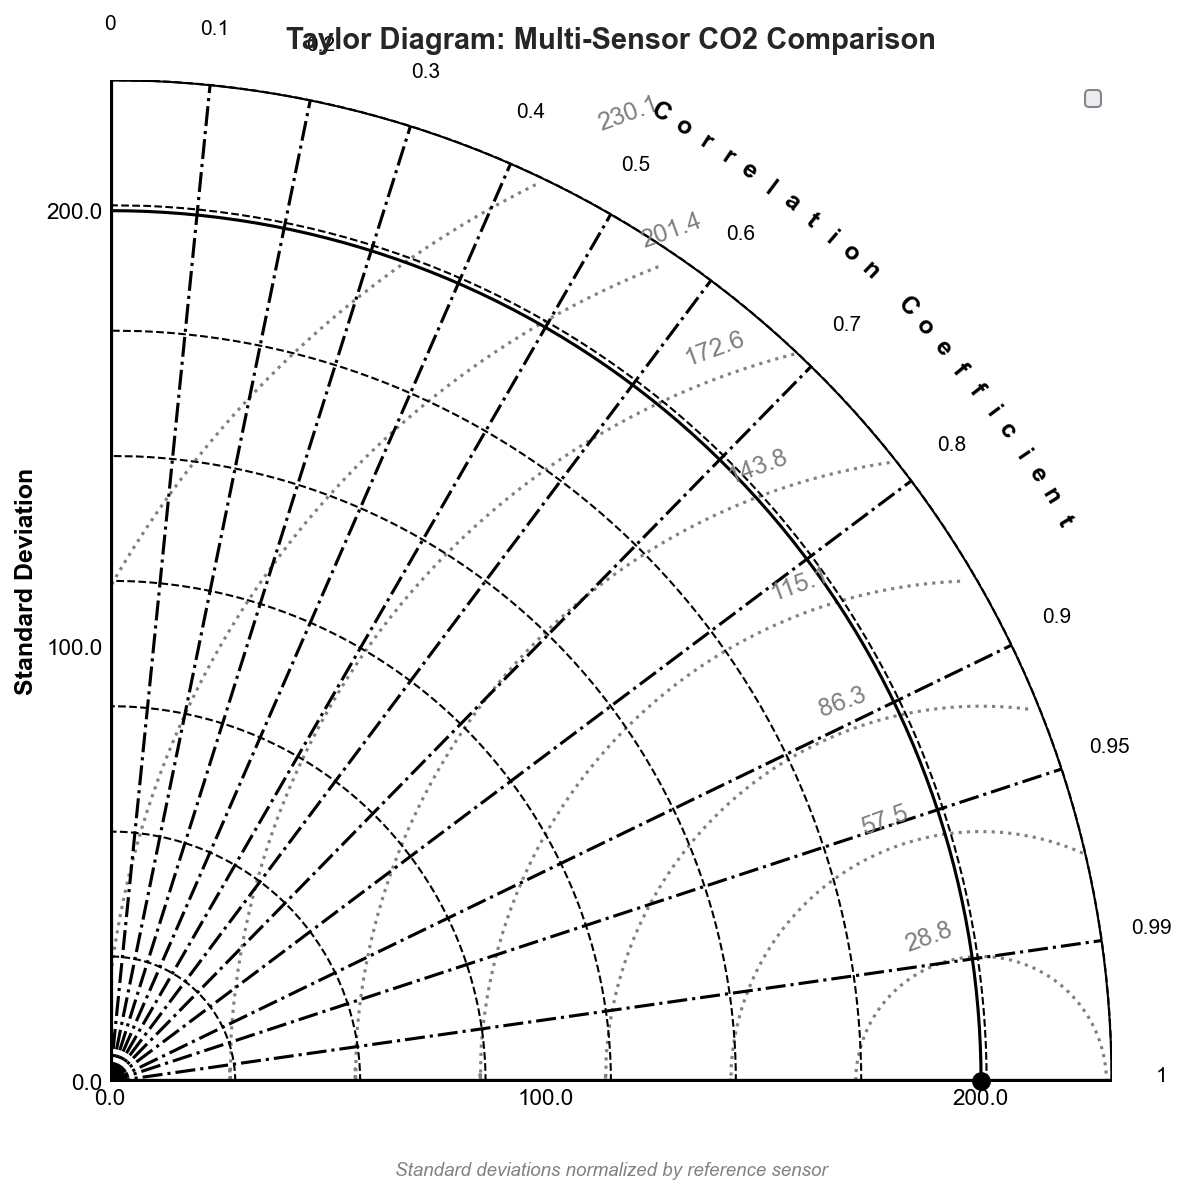

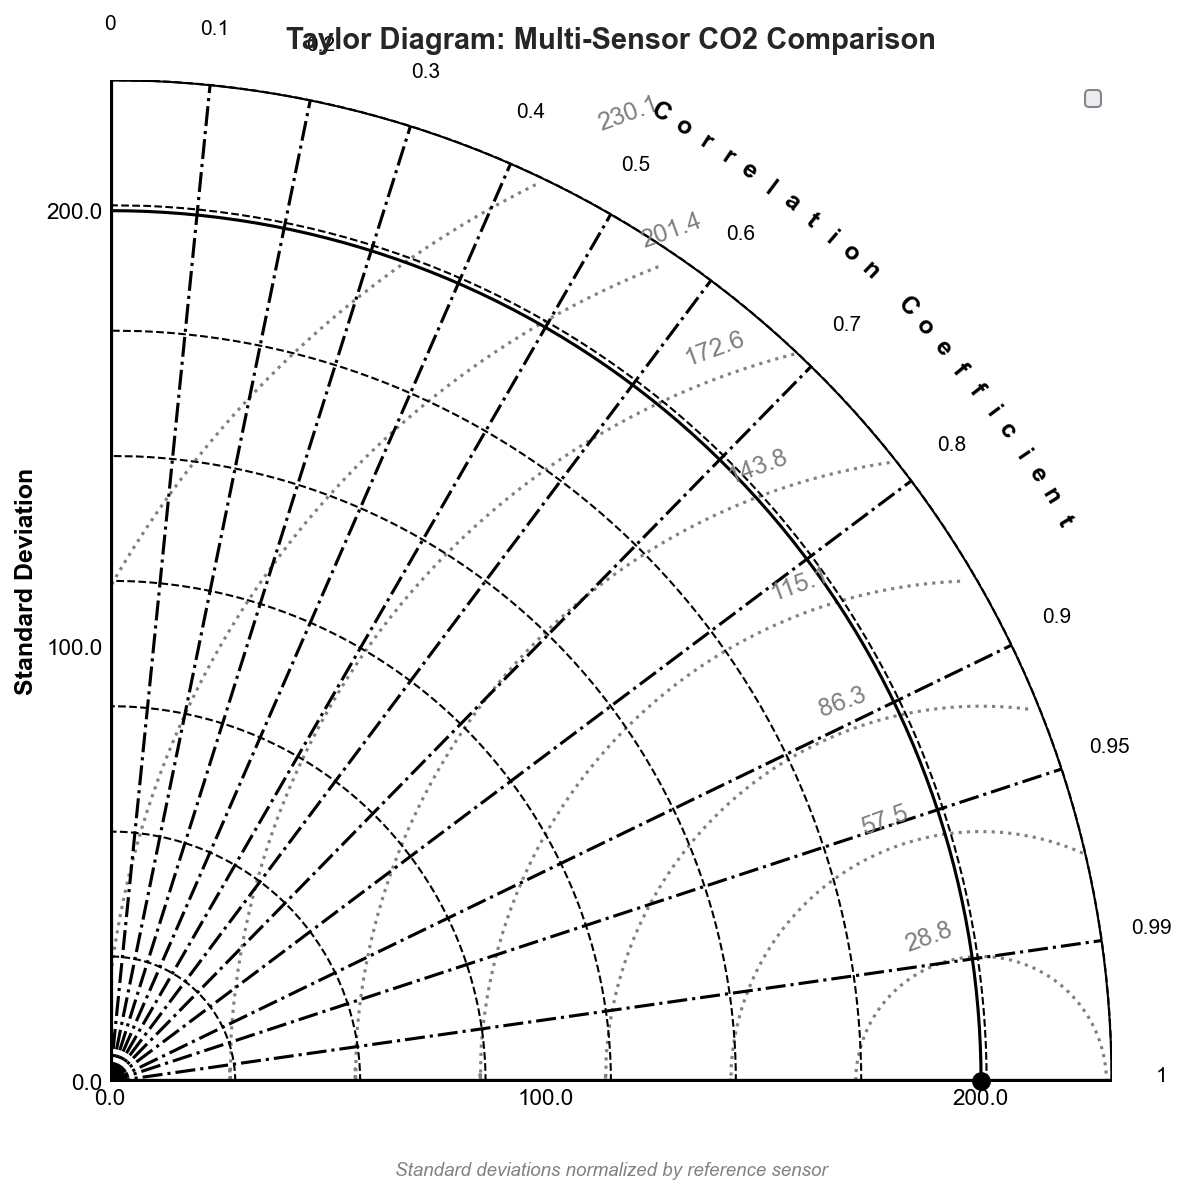

In [3]:
from src.visualization import TaylorDiagram

taylor = TaylorDiagram(config.output_dir / "plots")
taylor.plot_from_config(config, normalize=True)

In [ ]:
from src.visualization import generate_all_plots

# Generate all standard plots
generate_all_plots(config)

In [7]:
from src.merger import merge_all_sensors

merged = merge_all_sensors(
    individual_dir=config.output_dir,
    sensor_names=[s.name for s in config.sensors]
)

print(f"Merged dataset shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
print(f"\nColumns: {list(merged.columns)}")

2025-12-09 20:06:49,448 - src.merger - INFO - Merging 5 sensors...
2025-12-09 20:06:49,448 - src.merger - INFO -   Loading CO2_SCT1_2M...
2025-12-09 20:06:49,465 - src.merger - INFO -     7053 rows (2024-09-12 12:20:00 to 2024-10-31 23:10:00)
2025-12-09 20:06:49,466 - src.merger - INFO -   Loading CO2_30M_A...
2025-12-09 20:06:49,482 - src.merger - INFO -     6095 rows (2024-09-19 11:10:00 to 2024-11-11 10:40:00)
2025-12-09 20:06:49,483 - src.merger - INFO -   Loading CO2_30M_B...
2025-12-09 20:06:49,492 - src.merger - INFO -     6293 rows (2024-09-19 11:10:00 to 2024-11-11 10:40:00)
2025-12-09 20:06:49,492 - src.merger - INFO -   Loading CO2_30M_C...
2025-12-09 20:06:49,503 - src.merger - INFO -     4290 rows (2024-10-02 09:30:00 to 2024-10-31 23:30:00)
2025-12-09 20:06:49,504 - src.merger - INFO -   Loading LGR_30M...
2025-12-09 20:06:49,540 - src.merger - INFO -     8784 rows (2024-09-01 00:00:00 to 2024-10-31 23:50:00)
2025-12-09 20:06:49,541 - src.merger - INFO -   Merging on time

InvalidIndexError: Reindexing only valid with uniquely valued Index objects